In [26]:

cluster_df.to_csv("/content/music_songs_with_clusters.csv", index=False)

print("Files available:")
!ls -lh /content/music_songs_with_clusters.csv


Files available:
-rw-r--r-- 1 root root 9.0M Oct 14 16:54 /content/music_songs_with_clusters.csv


In [25]:

print("=" * 50)
print("MUSIC PLAYLIST ANALYSIS AND RECOMMENDATION SYSTEM")
print("=" * 50)

print("\n1. DATASET SUMMARY")
print("Total songs used for clustering:", len(cluster_df))
print("Unique songs in recommendation system:", len(recommendation_df))
print("Playlist genres:", df["playlist_genre"].nunique())
print("Unique playlist names:", df["playlist_name"].nunique())

print("\n2. CLUSTERING RESULTS")
print("Number of clusters:", cluster_df["cluster"].nunique())
print("Silhouette Score:", round(silhouette, 3))

print("\n3. CLUSTER DISTRIBUTION")
display(cluster_df["cluster"].value_counts().sort_index().to_frame("Number of Songs"))

print("\n4. MOST POPULAR PLAYLIST GENRES")
display(
    df.groupby("playlist_genre")["track_popularity"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
    .to_frame("Average Popularity")
)

print("\n5. RECOMMENDATION SYSTEM")
print("Recommendation function is ready to use.")
print("Example: recommend_songs('Shape of You', 5)")


MUSIC PLAYLIST ANALYSIS AND RECOMMENDATION SYSTEM

1. DATASET SUMMARY
Total songs used for clustering: 32828
Unique songs in recommendation system: 28352
Playlist genres: 6
Unique playlist names: 449

2. CLUSTERING RESULTS
Number of clusters: 6
Silhouette Score: 0.157

3. CLUSTER DISTRIBUTION


,Number of Songs
cluster,
0,10659
1,2138
2,4638
3,2465
4,4325
5,8603



4. MOST POPULAR PLAYLIST GENRES


,Average Popularity
playlist_genre,
pop,47.74
latin,47.04
rap,43.24
rock,41.73
r&b,41.22
edm,34.83



5. RECOMMENDATION SYSTEM
Recommendation function is ready to use.
Example: recommend_songs('Shape of You', 5)


In [24]:

# Save the cleaned dataset with cluster labels
cluster_df.to_csv(
    "/content/music_songs_with_clusters.csv",
    index=False
)

# Save a sample recommendation result
if recommendations is not None:
    recommendations.to_csv(
        "/content/song_recommendations.csv",
        index=False
    )

print("Project outputs saved successfully!")
print("Clustering silhouette score:", round(silhouette, 3))


Project outputs saved successfully!
Clustering silhouette score: 0.157


In [23]:

song_input = input("Enter a song name: ")
recommendations = recommend_songs(song_input, n_recommendations=5)

if recommendations is not None:
    display(recommendations)


Enter a song name: I Don't Care (with Justin Bieber) 
Selected song: I Don't Care (with Justin Bieber) - Loud Luxury Remix
Artist: Ed Sheeran

Recommended songs:


,track_name,track_artist,playlist_genre,track_popularity,similarity_score
0,I Miss You (feat. Julia Michaels) - Cahill Remix,Clean Bandit,edm,46,0.994
1,Rise - TV Noise Ibiza Mix,Jonas Blue,edm,46,0.978
2,Name & Number,Shift K3Y,pop,30,0.969
3,Who's Got Your Love,Cheat Codes,pop,70,0.964
4,Who's Got Your Love,Cheat Codes,pop,64,0.964


In [22]:

recommend_songs("Shape of You", n_recommendations=5)


Selected song: Shape of You
Artist: Ed Sheeran

Recommended songs:


,track_name,track_artist,playlist_genre,track_popularity,similarity_score
0,Shape of You,Ed Sheeran,latin,75,1.000
1,Brujeria,El Gran Combo De Puerto Rico,latin,55,0.963
2,Quizas - Remix,Tony Dize,latin,2,0.960
3,On The Low,Burna Boy,r&b,74,0.957
4,Me Quedaré Contigo,El Micha,latin,51,0.956


In [21]:

# Remove repeated track IDs so the same song isn't recommended multiple times
unique_mask = ~cluster_df["track_id"].duplicated()

recommendation_df = (
    cluster_df.loc[unique_mask]
    .reset_index(drop=True)
)

X_recommend = X_scaled[unique_mask.to_numpy()]

def recommend_songs(song_name, n_recommendations=5):
    # Find songs matching the entered name
    matches = recommendation_df[
        recommendation_df["track_name"].str.contains(
            song_name, case=False, na=False, regex=False
        )
    ]

    if matches.empty:
        print("Song not found. Try another song name.")
        return None

    # Prefer an exact title match when available
    exact_matches = matches[
        matches["track_name"].str.lower() == song_name.lower()
    ]

    if not exact_matches.empty:
        matches = exact_matches

    # Select the most popular match if multiple matches exist
    song_index = matches["track_popularity"].idxmax()

    # Calculate similarity between the selected song and all songs
    similarities = cosine_similarity(
        X_recommend[song_index].reshape(1, -1),
        X_recommend
    ).flatten()

    # Sort by highest similarity
    ranked_indices = np.argsort(similarities)[::-1]

    # Exclude the selected song itself
    selected_track_id = recommendation_df.loc[song_index, "track_id"]
    results = []

    for idx in ranked_indices:
        if recommendation_df.loc[idx, "track_id"] == selected_track_id:
            continue

        results.append(idx)

        if len(results) == n_recommendations:
            break

    if not results:
        print("No recommendations available.")
        return None

    output = recommendation_df.loc[
        results,
        ["track_name", "track_artist", "playlist_genre",
         "track_popularity"]
    ].copy()

    output["similarity_score"] = np.round(similarities[results], 3)

    print("Selected song:", recommendation_df.loc[song_index, "track_name"])
    print("Artist:", recommendation_df.loc[song_index, "track_artist"])
    print("\nRecommended songs:")

    return output.reset_index(drop=True)


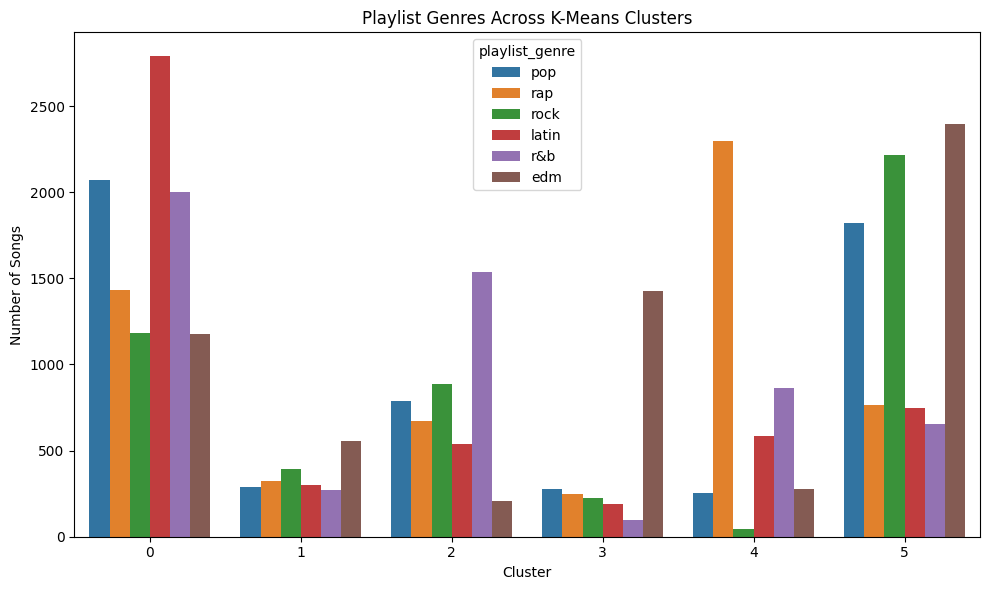

playlist_genre,edm,latin,pop,r&b,rap,rock
cluster,,,,,,
0,1179,2789,2071,2003,1432,1185
1,556,301,291,273,325,392
2,209,540,790,1539,673,887
3,1424,190,279,99,248,225
4,279,585,253,865,2300,43
5,2396,748,1823,652,765,2219


In [20]:

plt.figure(figsize=(10, 6))

sns.countplot(
    data=cluster_df,
    x="cluster",
    hue="playlist_genre"
)

plt.title("Playlist Genres Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Songs")
plt.tight_layout()
plt.show()

display(pd.crosstab(cluster_df["cluster"], cluster_df["playlist_genre"]))


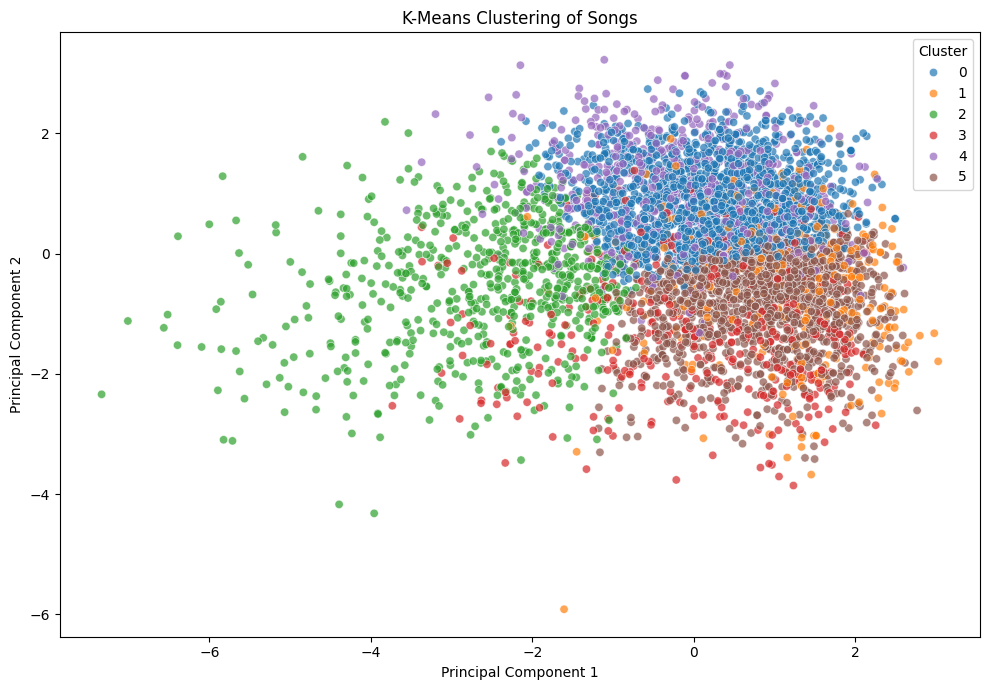

In [19]:

# Reduce features to two dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

cluster_df["PCA1"] = X_pca[:, 0]
cluster_df["PCA2"] = X_pca[:, 1]

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=cluster_df.sample(min(5000, len(cluster_df)), random_state=42),
    x="PCA1",
    y="PCA2",
    hue="cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("K-Means Clustering of Songs")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [18]:

# Build and train the model
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
cluster_df["cluster"] = kmeans.fit_predict(X_scaled)

# Evaluate clustering quality
silhouette = silhouette_score(
    X_scaled,
    cluster_df["cluster"],
    sample_size=min(5000, len(cluster_df)),
    random_state=42
)

print("K-Means model trained successfully!")
print("Number of clusters:", cluster_df["cluster"].nunique())
print("Silhouette Score:", round(silhouette, 3))


K-Means model trained successfully!
Number of clusters: 6
Silhouette Score: 0.157


In [17]:

# Select audio features for clustering
clustering_features = [
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "valence",
    "speechiness",
    "liveness",
    "tempo",
    "loudness"
]

# Keep rows with complete audio features
cluster_df = df.dropna(subset=clustering_features).copy()

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_df[clustering_features])

print("Data ready for clustering!")
print("Number of songs:", len(cluster_df))
print("Number of features:", len(clustering_features))


Data ready for clustering!
Number of songs: 32828
Number of features: 9


In [16]:

# Get unique feature pairs
correlation_pairs = correlation_matrix.unstack()
correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0) !=
    correlation_pairs.index.get_level_values(1)
]

# Remove duplicate pairs
correlation_pairs.index = [
    tuple(sorted(pair)) for pair in correlation_pairs.index
]
correlation_pairs = correlation_pairs[~correlation_pairs.index.duplicated()]

print("Top 5 Positive Correlations:")
display(correlation_pairs.sort_values(ascending=False).head(5).to_frame("Correlation"))

print("Top 5 Negative Correlations:")
display(correlation_pairs.sort_values().head(5).to_frame("Correlation"))


Top 5 Positive Correlations:


,Correlation
"(energy, loudness)",0.676662
"(danceability, valence)",0.330538
"(danceability, speechiness)",0.181808
"(energy, liveness)",0.161317
"(energy, valence)",0.151050


Top 5 Negative Correlations:


,Correlation
"(acousticness, energy)",-0.539732
"(acousticness, loudness)",-0.361646
"(danceability, tempo)",-0.184132
"(instrumentalness, valence)",-0.175406
"(instrumentalness, track_popularity)",-0.150003


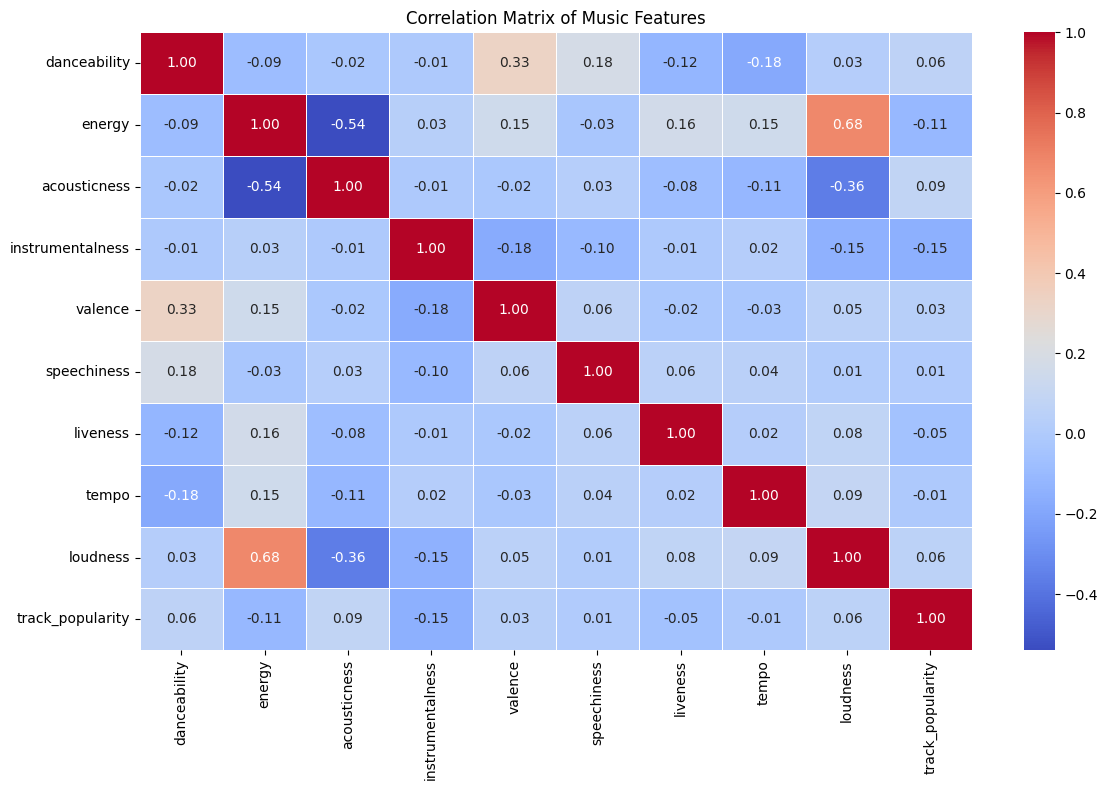

In [15]:

# Select numerical audio features
audio_features = [
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "valence",
    "speechiness",
    "liveness",
    "tempo",
    "loudness",
    "track_popularity"
]

# Calculate the correlation matrix
correlation_matrix = df[audio_features].corr()

# Visualize the correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Music Features")
plt.tight_layout()
plt.show()


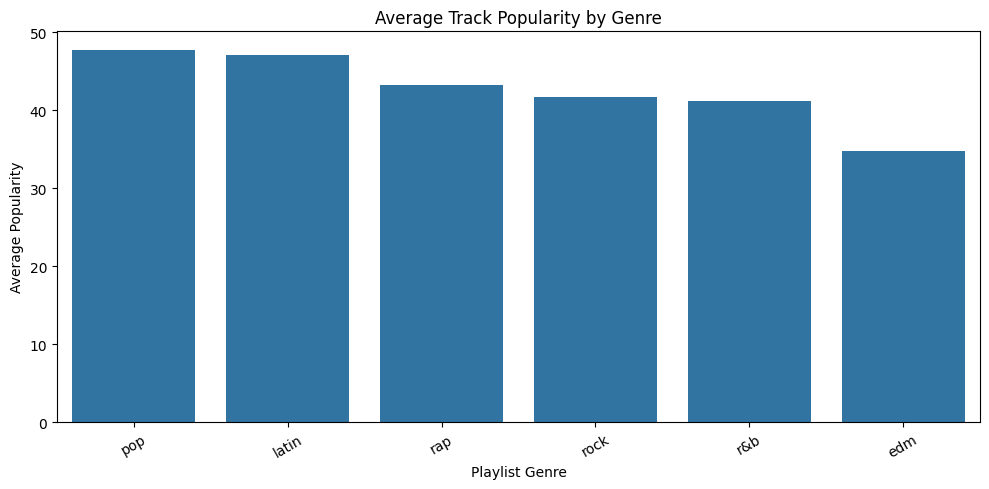

,Average Popularity
playlist_genre,
pop,47.744870
latin,47.044828
rap,43.238029
rock,41.728338
r&b,41.223532
edm,34.833526


In [14]:
genre_popularity = (
    df.groupby("playlist_genre")["track_popularity"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=genre_popularity.index,
    y=genre_popularity.values
)

plt.title("Average Track Popularity by Genre")
plt.xlabel("Playlist Genre")
plt.ylabel("Average Popularity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(genre_popularity.to_frame("Average Popularity"))

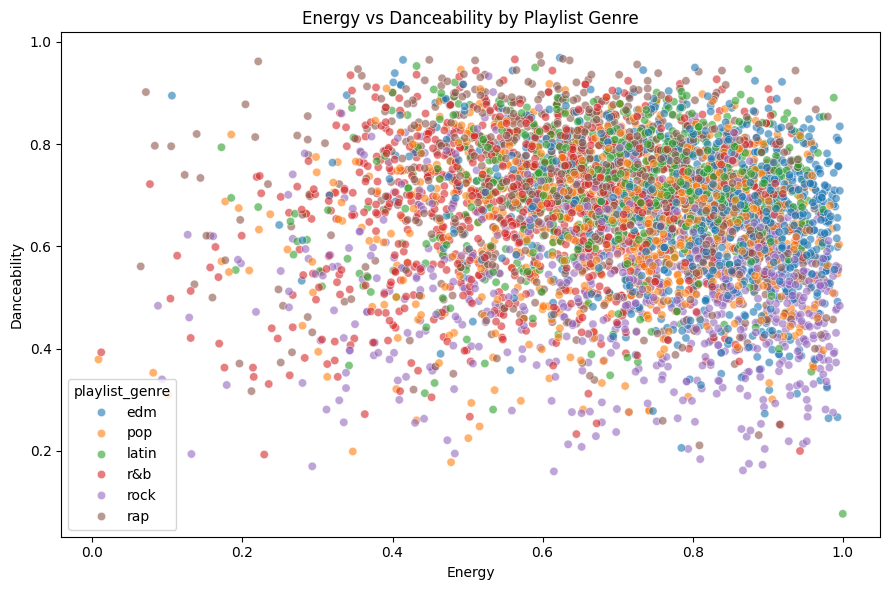

In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df.sample(min(5000, len(df)), random_state=42),
    x="energy",
    y="danceability",
    hue="playlist_genre",
    alpha=0.6
)

plt.title("Energy vs Danceability by Playlist Genre")
plt.xlabel("Energy")
plt.ylabel("Danceability")
plt.tight_layout()
plt.show()

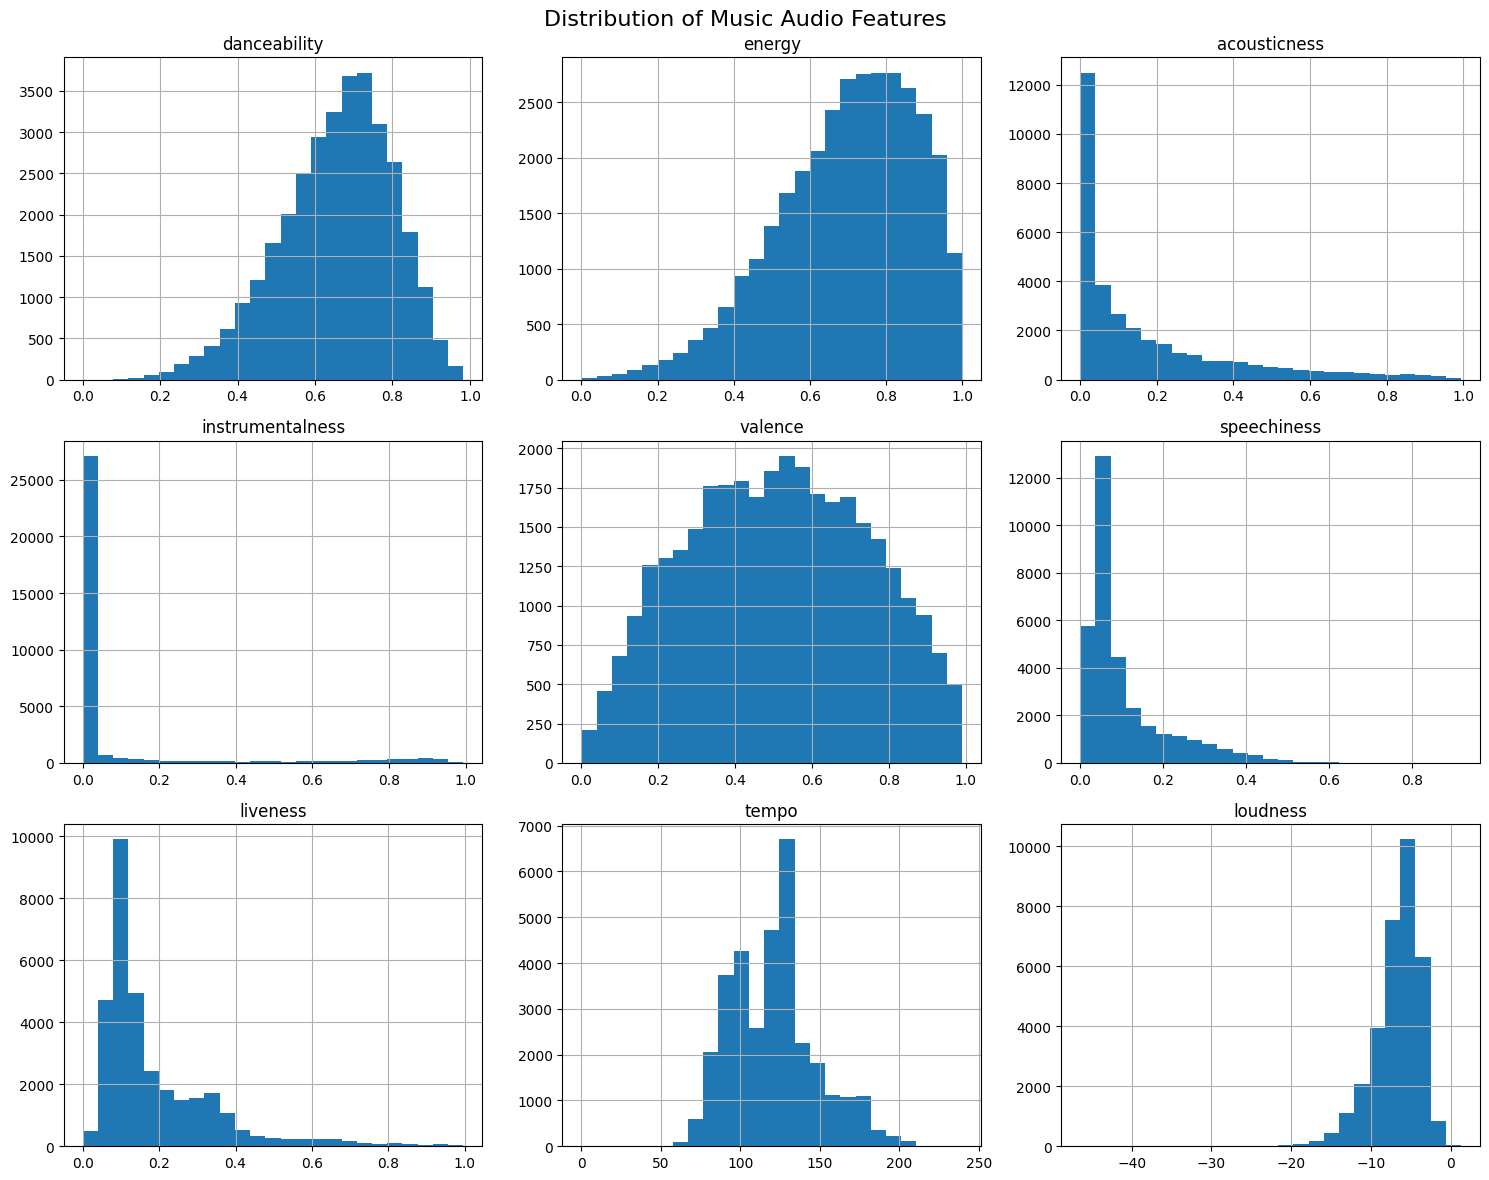

In [12]:
audio_features = [
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "valence",
    "speechiness",
    "liveness",
    "tempo",
    "loudness"
]

df[audio_features].hist(
    figsize=(15, 12),
    bins=25
)

plt.suptitle("Distribution of Music Audio Features", fontsize=16)
plt.tight_layout()
plt.show()

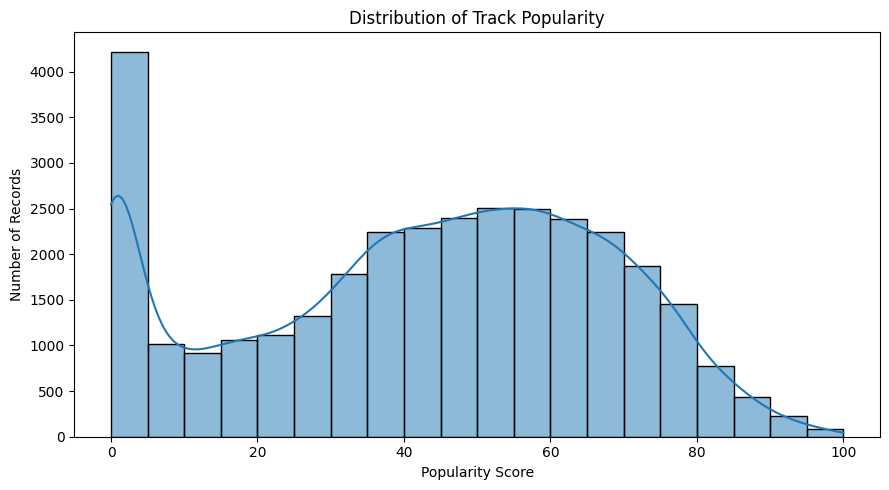

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="track_popularity",
    bins=20,
    kde=True
)

plt.title("Distribution of Track Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1198/2677562835.py:9: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


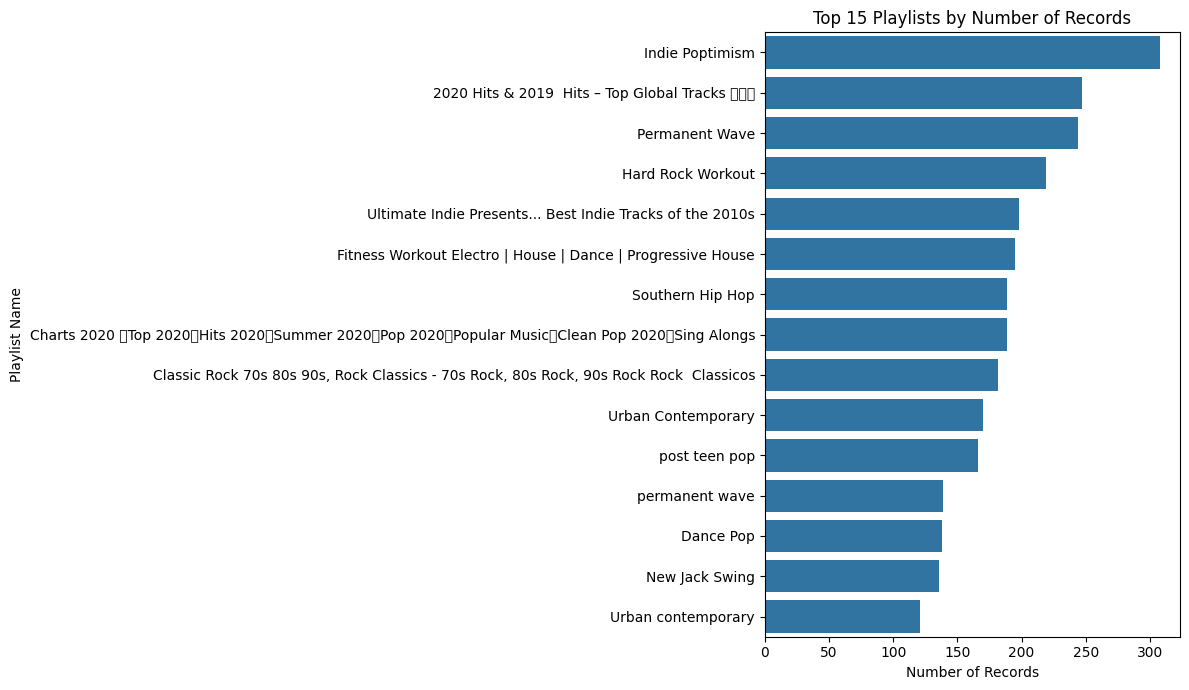

In [10]:
top_playlists = df["playlist_name"].value_counts().head(15)

plt.figure(figsize=(12, 7))
sns.barplot(x=top_playlists.values, y=top_playlists.index)

plt.title("Top 15 Playlists by Number of Records")
plt.xlabel("Number of Records")
plt.ylabel("Playlist Name")
plt.tight_layout()
plt.show()

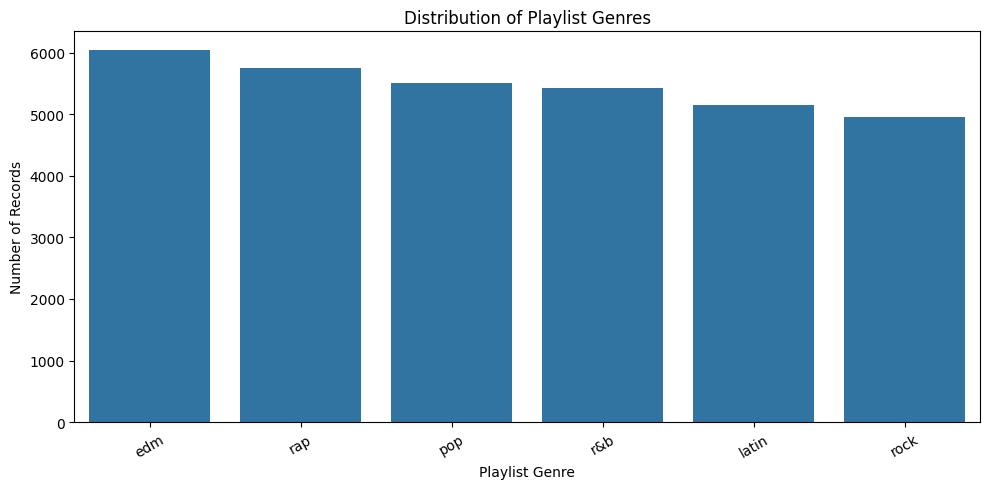

In [9]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="playlist_genre",
    order=df["playlist_genre"].value_counts().index
)

plt.title("Distribution of Playlist Genres")
plt.xlabel("Playlist Genre")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [8]:
df.to_csv("cleaned_music_playlist_data.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (32828, 23)


In [7]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(list(numerical_columns))

display(df[numerical_columns].describe().T)

Numerical columns:
['track_popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']


,count,mean,std,min,25%,50%,75%,max
track_popularity,32828.0,42.483551,24.980476,0.000000,24.00000,45.000000,62.00000,100.000
danceability,32828.0,0.654850,0.145092,0.000000,0.56300,0.672000,0.76100,0.983
energy,32828.0,0.698603,0.180916,0.000175,0.58100,0.721000,0.84000,1.000
key,32828.0,5.373949,3.611572,0.000000,2.00000,6.000000,9.00000,11.000
loudness,32828.0,-6.719529,2.988641,-46.448000,-8.17125,-6.166000,-4.64500,1.275
mode,32828.0,0.565737,0.495667,0.000000,0.00000,1.000000,1.00000,1.000
speechiness,32828.0,0.107053,0.101307,0.000000,0.04100,0.062500,0.13200,0.918
acousticness,32828.0,0.175352,0.219644,0.000000,0.01510,0.080400,0.25500,0.994
instrumentalness,32828.0,0.084760,0.224245,0.000000,0.00000,0.000016,0.00483,0.994
liveness,32828.0,0.190175,0.154313,0.000000,0.09270,0.127000,0.24800,0.996


In [6]:
print("Rows before cleaning:", len(df))

df = df.dropna(
    subset=["track_id", "track_name", "track_artist"]
).copy()

df = df.reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("Remaining missing values in essential columns:")
print(df[["track_id", "track_name", "track_artist"]].isnull().sum())

Rows before cleaning: 32833
Rows after cleaning: 32828
Remaining missing values in essential columns:
track_id        0
track_name      0
track_artist    0
dtype: int64


In [5]:
print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))
print("Duplicate rows removed successfully!")

Rows before removing duplicates: 32833
Rows after removing duplicates: 32833
Duplicate rows removed successfully!


Missing values in each column:
track_name          5
track_artist        5
track_album_name    5
dtype: int64


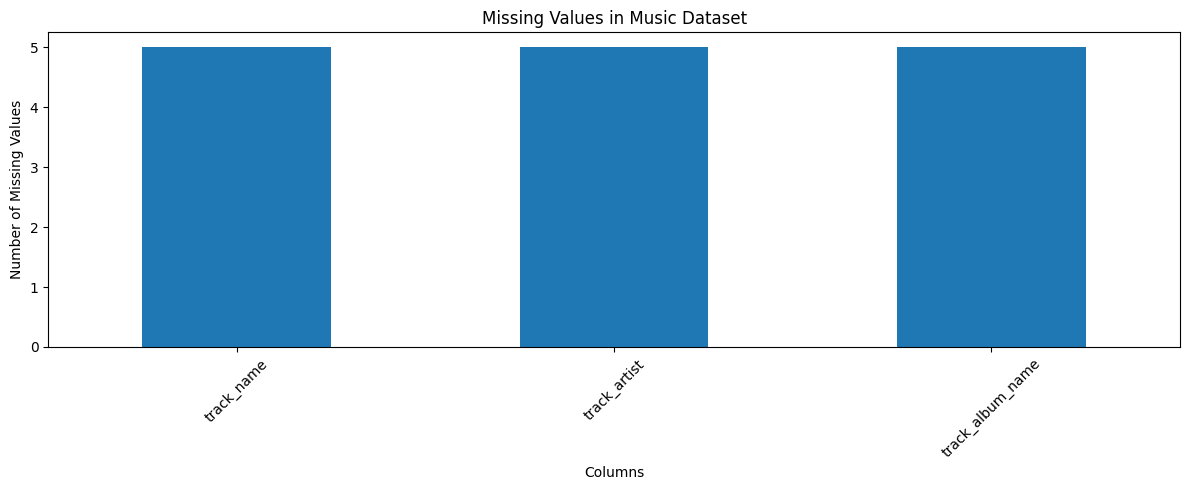

In [4]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

# Visualize missing values
plt.figure(figsize=(12, 5))
missing_values[missing_values > 0].plot(kind="bar")

plt.title("Missing Values in Music Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


In [2]:
df = pd.read_csv('/content/spotify_playlist_dataset.csv')

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (32833, 23)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

print("All libraries imported successfully!")

All libraries imported successfully!
